# Neural Network Training

### Import Libraries

In [2]:
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from numpy.random import randn, seed

### Data Generation

In [3]:
url = "https://www.itl.nist.gov/div898/strd/nls/data/LINKS/DATA/Gauss2.dat"
beacon = "Data:"
r = requests.get(url)
data = r.text
data = data[data.rfind(beacon) + len(beacon):]
data = np.array([v.split() for v in data.split("\n")][1:-1]).astype("float")

In [4]:
df = pd.DataFrame(data)
print(df.head())

          0    1
0  97.58776  1.0
1  97.76344  2.0
2  96.56705  3.0
3  92.52037  4.0
4  91.15097  5.0


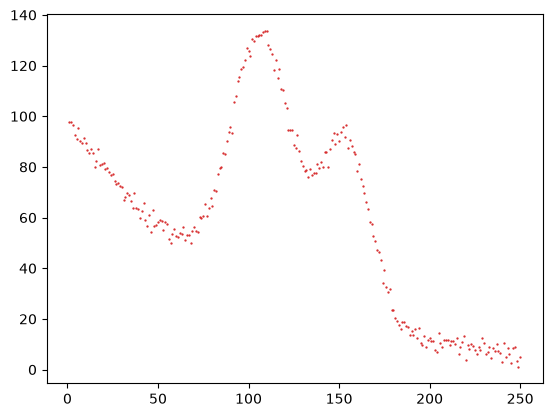

In [5]:
x = data[:, 1]
y = data[:, 0]
plt.scatter(x, y, s=0.4, c="tab:red")

## Learning

### Reshape and Standardize the Data

Reshaping does not change the data but helps in performing batch operations.

In [ ]:
print("Shape Before:")
print(x.shape, y.shape)

N = len(df)
x_reshaped = x.reshape(N, 1, 1)
y_reshaped = x.reshape(N, 1, 1)

print("\nShape After:")
print(x_reshaped.shape, y_reshaped.shape)

Shape Before:
(250,) (250,)

Shape After:
(250, 1, 1) (250, 1, 1)


Standardizing is important because raw $x$ runs from 1 to 250, so activation function can saturate for almost every neuron and gradients vanish. $tanh()$ starts to saturate near $-1$ and $+1$.

(250, 1, 1) (250, 1, 1)


Text(0.5, 1.0, 'After Scaling')

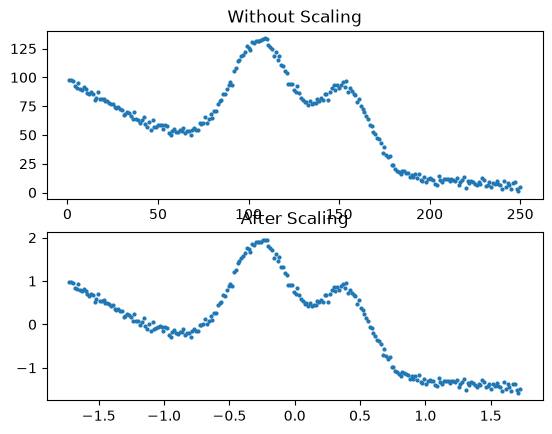

In [7]:
x_mean, x_std = x.mean(), x.std()
y_mean, y_std = y.mean(), y.std()

x_scaled = ((x - x_mean) / x_std).reshape(N, 1, 1)
y_scaled = ((y - y_mean) / y_std).reshape(N, 1, 1)
print(x_scaled.shape, y_scaled.shape)

plt.figure()
plt.subplot(2,1,1)
plt.scatter(x, y, s=4)
plt.title("Without Scaling")
plt.subplot(2,1,2)
plt.scatter(x_scaled, y_scaled, s=4)
plt.title("After Scaling")


### Train-Test Split

Because the data is sequential, the correct approach is to select random indices proportionally so that train set has 80% of data and test set has remaining 20%.

In [47]:
N_train = int(0.8*N)

# train_indices = np.arange(0, N_train, 1)
# test_indices = np.arange(N_train, N, 1)

# x_train = x_scaled[train_indices]
# y_train = y_scaled[train_indices]

# x_test = x_scaled[test_indices]
# y_test = y_scaled[test_indices]

rng = np.random.default_rng(42)
idx = rng.permutation(N)

N_train = int(0.7 * N)
train_indices = np.sort(idx[:N_train])
test_indices = np.sort(idx[N_train:])

x_train, y_train = x_scaled[train_indices], y_scaled[train_indices]
x_test,  y_test  = x_scaled[test_indices],  y_scaled[test_indices]

In [28]:
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(175, 1, 1) (175, 1, 1)
(75, 1, 1) (75, 1, 1)


Text(0.5, 1.0, 'Test Set')

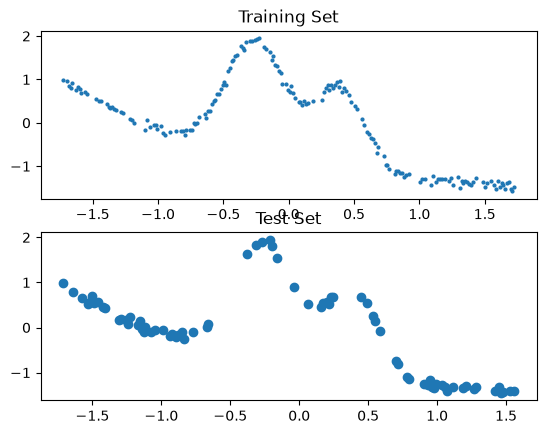

In [48]:
plt.figure()
plt.subplot(2,1,1)
plt.scatter(x_train, y_train, s=4)
plt.title("Training Set")
plt.subplot(2,1,2)
plt.scatter(x_test, y_test)
plt.title("Test Set")


### Activation Function

In [40]:
# Define activation function
s  = lambda x: np.tanh(x)
ds = lambda x: 1 - np.tanh(x) ** 2

### Dimensionality

Input Size: 1D

Hidden Layers: 2

* 1st Layer: 8 units
* 2nd Layer: 16 units

Output Size: 1D

Number of rows in the current layer will be number of hidden units (or neurons) in current layer.
Number of columns in current layer will be number of hidden units (or neurons) in previous layer.

W1 size: (8, 1)         : 1 input to 8 neurons in next layer

W2 size: (16, 8)        : 8 inputs to 16 neurons in next layer

W3 size: (1, 16)        : 16 inputs to 1 neuron in next layer

In [55]:
# Initialize weights randomly using Uniform distribution
# Uniform distribution selects random number between low and high
# size = (i, m, n) means i sample(s) of m-by-n matrix

In = 1                  # Number of input(s)
L1 = 20                 # Number of neurons in Layer-1
L2 = 20                 # Number of neurons in Layer-2
Out = 1                 # Number of neurons in output layer

np.random.seed(0)               # select seed for reproducible results
W1 = np.random.uniform(low=-1, high=1, size=(1,  L1,  In))
W2 = np.random.uniform(low=-1, high=1, size=(1,  L2,  L1))
W3 = np.random.uniform(low=-1, high=1, size=(1,  Out, L2))

In [56]:
# Initialize biases randomly using Uniform distribution

# 8 outputs by the first layer
b1 = np.random.uniform(low=-1, high=1, size=(1, L1, 1))
# 16 outputs by the second layer
b2 = np.random.uniform(low=-1, high=1, size=(1, L2, 1))
# 1 output by the third layer
b3 = np.random.uniform(low=-1, high=1, size=(1, Out, 1))

### Training Loop

$$\mathbf h_i=W_1x_i+\mathbf b_1$$
 
$$\mathbf g_i=W_2\sigma(\mathbf h_i)+\mathbf b_2$$
 
$$f_i=W_3\sigma(\mathbf g_i)+b_3$$

Backward pass (row-vector deltas)
 
$$\delta_f=2(f_i-y_i)\quad(1\times1)$$
 
$$\delta_g=\delta_f\,W_3\,\mathrm{diag}(\sigma'(\mathbf g_i))\quad(1\times16)$$
 
$$\delta_h=\delta_g\,W_2\,\mathrm{diag}(\sigma'(\mathbf h_i))\quad(1\times8)$$
 
Per-example gradients
 
$$\frac{\partial L_i}{\partial W_1}=\delta_h^{\top}x_i,\qquad \frac{\partial L_i}{\partial W_2}=\delta_g^{\top}\sigma(\mathbf h_i)^{\top},\qquad \frac{\partial L_i}{\partial W_3}=\delta_f\,\sigma(\mathbf g_i)^{\top}$$
 
$$\frac{\partial L_i}{\partial \mathbf b_1}=\delta_h^{\top},\qquad \frac{\partial L_i}{\partial \mathbf b_2}=\delta_g^{\top},\qquad \frac{\partial L_i}{\partial b_3}=\delta_f$$

Batch mean
 
(`np.mean(..., 0)` in the code)
 
$$\frac{\partial L}{\partial \theta}=\frac1N\sum_{i=1}^N\frac{\partial L_i}{\partial \theta},\qquad \theta\in\{W_1,W_2,W_3,\mathbf b_1,\mathbf b_2,b_3\}$$

(175, 20, 1) (175, 20, 1) (175, 1, 1)
(175, 1, 20) (175, 1, 20) (175, 1, 1)
(1, 20, 1) (1, 20, 20) (1, 1, 20)
(1, 20, 1) (1, 20, 1) (1, 1, 1)


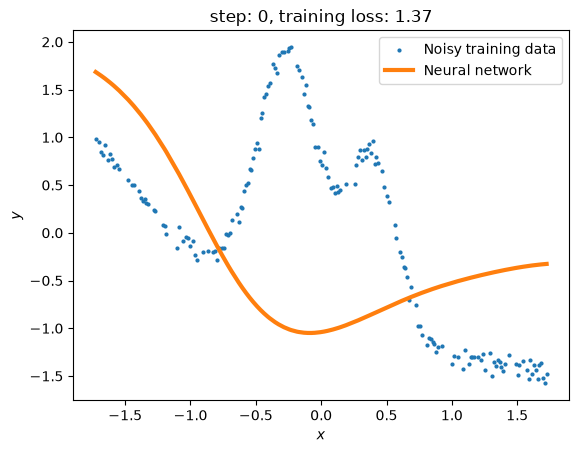

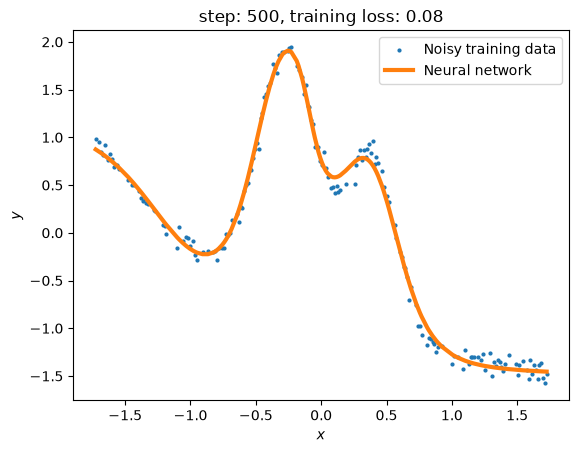

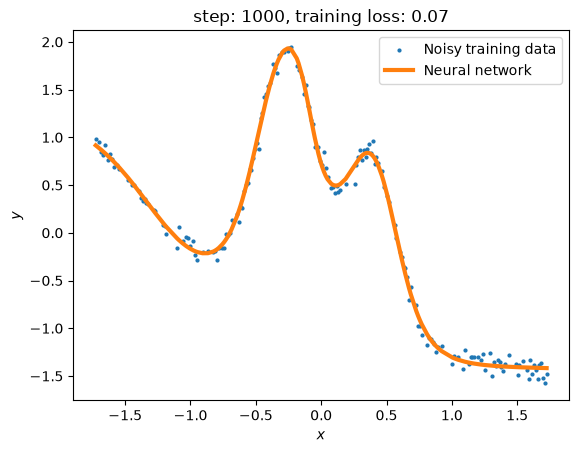

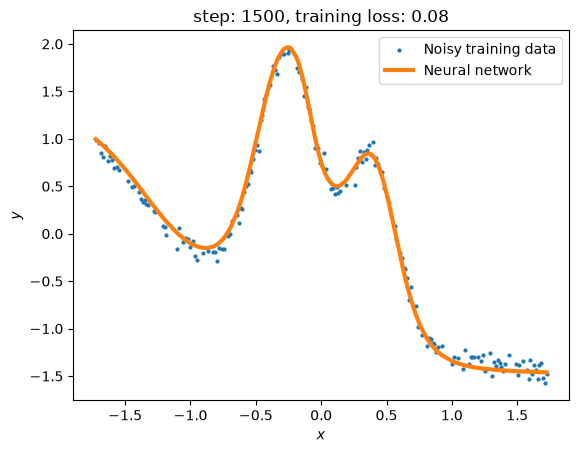

In [ ]:
epochs = 2000           # iterate over whole data 1000 times
lr = 0.1               # learning rate

for i in range(epochs):

    # Forward pass
    h = W1 @ x_train + b1
    g = W2 @ s(h) + b2
    f = W3 @ s(g) + b3

    # Back-propagate
    diag_g = ds(g)*np.expand_dims(np.eye(L2),0)
    diag_h = ds(h)*np.expand_dims(np.eye(L1),0)

    dldf = 2 * (f - y_train)
    dldg = (dldf @ W3) @ diag_g
    dldh = (dldg @ W2) @ diag_h

    dW1 = (dldh * x_train).transpose(0, 2, 1) 
    dW2 = (dldg * s(h)).transpose(0, 2, 1)  
    dW3 = (dldf * s(g)).transpose(0, 2, 1) 

    db1 = dldh.transpose(0, 2, 1)
    db2 = dldg.transpose(0, 2, 1)
    db3 = dldf.transpose(0, 2, 1) 

    # get mean gradient
    dW1 = np.mean(dW1, 0, keepdims=True)
    dW2 = np.mean(dW2, 0, keepdims=True)
    dW3 = np.mean(dW3, 0, keepdims=True)
    db1 = np.mean(db1, 0, keepdims=True)
    db2 = np.mean(db2, 0, keepdims=True)
    db3 = np.mean(db3, 0, keepdims=True)

    # Gradient descent
    W1 -= lr * dW1
    W2 -= lr * dW2
    W3 -= lr * dW3
    b1 -= lr * db1
    b2 -= lr * db2
    b3 -= lr * db3

    if i == 0: 
        print(h.shape, g.shape, f.shape)
        print(dldh.shape, dldg.shape, dldf.shape)
        print(dW1.shape, dW2.shape, dW3.shape)
        print(db1.shape, db2.shape, db3.shape)
            
    if i % 500 == 0: 
        
        # get loss value
        l = np.sqrt(np.mean((f-y_train)**2)) 
        
        # Plot the training data
        plt.figure()
        plt.title(f"step: {i}, training loss: {l:.2f}")
        plt.scatter(x_train[:,0,0], y_train[:,0,0], label="Noisy training data", s=4)
        plt.plot(x_train[:,0,0], f[:,0,0], lw=3, label="Neural network", c='tab:orange')
        plt.xlabel("$x$")
        plt.ylabel("$y$")
        plt.legend()
        plt.show()

### Evaluation

train RMSE: 0.0637   R2: 0.9961
test  RMSE: 0.0585   R2: 0.9961


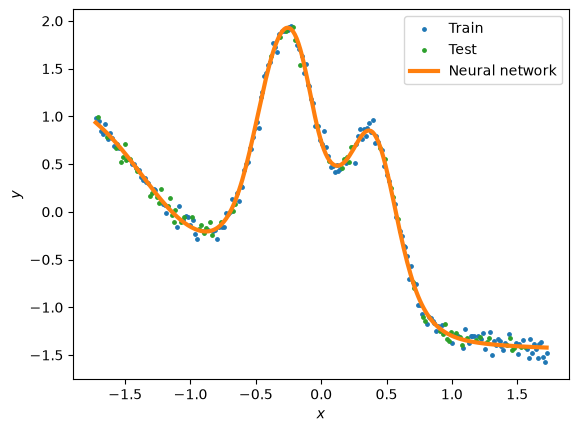

In [58]:
# Forward pass on train and test
def predict(x):
    h = W1 @ x + b1
    g = W2 @ s(h) + b2
    return W3 @ s(g) + b3

f_train = predict(x_train)
f_test = predict(x_test)

# Metrics (scaled units)
def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))
def r2(a, b): return 1 - np.sum((a - b) ** 2) / np.sum((a - np.mean(a)) ** 2)

print(f"train RMSE: {rmse(f_train, y_train):.4f}   R2: {r2(y_train, f_train):.4f}")
print(f"test  RMSE: {rmse(f_test, y_test):.4f}   R2: {r2(y_test, f_test):.4f}")

# Plot: full curve + train/test points
x_all = np.sort(x_scaled[:, 0, 0])
f_all = predict(x_all.reshape(-1, 1, 1))

plt.figure()
plt.scatter(x_train[:, 0, 0], y_train[:, 0, 0], s=6, label="Train")
plt.scatter(x_test[:, 0, 0], y_test[:, 0, 0], s=6, c="tab:green", label="Test")
plt.plot(x_all, f_all[:, 0, 0], lw=3, c="tab:orange", label="Neural network")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show()